<a href="https://colab.research.google.com/github/fforster/alerce-iucaa-2026/blob/main/01_multisurvey_database.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 · The ALeRCE multisurvey database

**ALeRCE multisurvey tutorial — IUCAA 2026** · ~45 min

Since October 2026 ALeRCE stores **ZTF and LSST in one PostgreSQL database** (schema `multisurvey`), published
through TAP as the schema **`alerce_tap`**. In this notebook we visit **every one of its 31 tables**, learn the
rules to join them, and write the small helper functions that we will reuse in the science notebooks.

**Contents**
1. The identity model: `oid`, `sid`, `tid`
2. The map of the database
3. Look-up tables (LUTs) and a `decode()` helper
4. Objects: `object`, `ztf_object`, `lsst_dia_object`
5. Light curves: `detection`, `forced_photometry`, `ztf_non_detection` and their survey extensions
6. ZTF auxiliary tables: `ztf_ps1`, `ztf_gaia`, `ztf_ss`, `ztf_dataquality`, `ztf_reference`
7. LSST solar-system tables: `lsst_ss_object`, `lsst_ss_detection`, `lsst_mpc_orbits`
8. Derived products: `magstat`, `feature`, `probability`
9. Crossmatches: `xmatch`, `allwise`, `gaiadr3_source`
10. Rules of thumb, and the `alerce_ms` library

The structure follows chapter 7 of the *ALeRCE book* (ALeRCE's internal design document).

In [1]:
import sys

if "google.colab" in sys.modules:
    !pip -q install pyvo astroquery
    !wget -q -N https://raw.githubusercontent.com/fforster/alerce-iucaa-2026/main/alerce_ms.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyvo

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

tap = pyvo.dal.TAPService("https://tap.alerce.online/tap")


def tap_query(adql, maxrec=1_000_000):
    """Run an ADQL query and return a pandas DataFrame."""
    return tap.search(adql, maxrec=maxrec).to_table().to_pandas()

> **Be gentle with the server.** ALeRCE services are free, shared and rate-limited per IP address. When a whole
> classroom shares one IP, avoid running loops of hundreds of queries; prefer one query that returns many rows.
> The `alerce_ms` library we import at the end caches every result on disk and retries politely.

## 1. The identity model

Every row about an astronomical object carries **two** keys:

| Key | Type | Meaning |
|---|---|---|
| `sid` | int2 | **survey id**: 0 = ZTF, 1 = LSST DIA object, 2 = LSST solar-system object |
| `oid` | int8 | object id **within that survey** |
| `tid` | int2 | telescope id: 0 = ZTF (Palomar), 1 = Rubin |

> 🔑 **Rule 1: an object is the pair `(oid, sid)`. Always join on both columns.** The same integer could
> in principle be an `oid` in two surveys.

> 🔑 **Rule 2: there is no cross-survey association.** A star observed by ZTF and by LSST is *two objects*. To link
> them you do a positional crossmatch (notebook 02).

**LSST** `oid` is simply Rubin's `diaObjectId`, e.g. `314003014107006318`.

**ZTF** names like `ZTF26aaonmha` are converted to integers. The name is a two-digit year plus seven lower-case
letters, i.e. a number in base 26. ALeRCE adds a *survey prefix* (ZTF = 1) in the top bits:
`oid = (1 << 55) + year·26⁷ + letters(base 26)`. Let us write the encoder and decoder:

In [2]:
def ztf_name_to_oid(name):
    """'ZTF26aaonmha' -> integer oid used in alerce_tap."""
    year, letters = int(name[3:5]), name[5:12]
    seq = sum((ord(c) - ord("a")) * 26 ** (6 - i) for i, c in enumerate(letters))
    return (1 << 55) + year * 26 ** 7 + seq


def oid_to_ztf_name(oid):
    """Inverse of ztf_name_to_oid."""
    value = int(oid) & ((1 << 55) - 1)          # remove the survey prefix
    year, seq = (value // 26 ** 7) % 100, value % 26 ** 7
    letters = ""
    for i in range(6, -1, -1):
        letters += chr(seq // 26 ** i + ord("a"))
        seq %= 26 ** i
    return f"ZTF{year:02d}{letters}"


oid = ztf_name_to_oid("ZTF26aaonmha")
print(oid, "->", oid_to_ztf_name(oid))

36029005852662990 -> ZTF26aaonmha


> ⚠️ The survey *prefix* inside the ZTF integer (ZTF = 1, ATLAS = 2, LSST = 3, …) is **not** the same numbering
> as `sid`. Never mix them.
>
> ⚠️ LSST ids are 64-bit integers: they do not fit in a JavaScript/JSON double. In Python they are fine, but never
> store them as `float`.

## 2. The map of the database

The TAP service describes itself in `TAP_SCHEMA`. Let us list the tables and their descriptions:

In [3]:
tables = tap_query("""
    SELECT table_name, description
    FROM TAP_SCHEMA.tables
    WHERE schema_name = 'alerce_tap'
""")
tables["table_name"] = tables.table_name.str.replace("alerce_tap.", "")
tables["description"] = tables.description.str.slice(0, 110)
tables

,table_name,description
0,object,\nThis table contains aggregated information a...
1,ztf_object,\nZTF-specific properties for astronomical obj...
2,lsst_dia_object,\nSummary catalog of transient and variable ob...
3,lsst_ss_object,\nProperties of solar system objects observed ...
4,lsst_mpc_orbits,\nComplete orbital solutions from the Minor Pl...
5,detection,\nGeneric detection table containing basic inf...
6,ztf_detection,\nIndividual detections from ZTF difference im...
7,lsst_detection,\nIndividual LSST Difference Image Analysis so...
8,lsst_ss_detection,\nIndividual LSST detections associated with s...
9,forced_photometry,\nGeneric forced photometry measurements acros...


They fall into a few families:

```
                   shared (all surveys)          ZTF extension            LSST extension
 objects        :  object                  ->    ztf_object               lsst_dia_object, lsst_ss_object
 light curves   :  detection               ->    ztf_detection            lsst_detection, lsst_ss_detection
                   forced_photometry       ->    ztf_forced_photometry    lsst_forced_photometry
                                                 ztf_non_detection        (none)
 ZTF extras     :                                ztf_ps1, ztf_gaia, ztf_ss, ztf_dataquality, ztf_reference
 LSST orbits    :                                                         lsst_mpc_orbits
 derived        :  magstat, feature, probability, xmatch
 classifiers    :  classifier, taxonomy
 catalogs       :  allwise, gaiadr3_source
 look-up tables :  sid_lut, band, feature_name_lut, feature_version_lut, catalog_id_lut
```

The **shared + extension** design is the key idea: every light-curve point is *one row* in a shared table
(`detection`: `oid, sid, measurement_id, mjd, ra, dec, band`) plus *one row* with the survey's native columns in its
extension table (`ztf_detection` has magnitudes, `lsst_detection` has fluxes and ~100 Rubin columns).

You can list the columns of any table with `TAP_SCHEMA.columns`:

In [4]:
def tap_columns(table):
    return tap_query(f"""
        SELECT column_name, datatype, unit, description
        FROM TAP_SCHEMA.columns
        WHERE table_name = 'alerce_tap.{table}'
    """)


tap_columns("object")

,column_name,datatype,unit,description
0,oid,long,,Internal object identifier
1,tid,short,,Telescope identifier
2,sid,short,,Survey identifier
3,meanra,double,deg,Mean right ascension (ICRS)
4,meandec,double,deg,Mean declination (ICRS)
5,sigmara,double,deg,Standard deviation of right ascension
6,sigmadec,double,deg,Standard deviation of declination
7,firstmjd,double,d,First observation MJD
8,lastmjd,double,d,Last observation MJD
9,deltamjd,double,d,Time span between first and last observation


## 3. Look-up tables

Large tables store small integers (`band = 2`, `feature_id = 27`, `class_id = 18`) instead of strings. The meaning of
each integer lives in a **look-up table** (LUT). They are tiny, so we download them all once.

### 3.1 `sid_lut`: surveys

In [5]:
sid_lut = tap_query("SELECT * FROM alerce_tap.sid_lut")
sid_lut

,sid,tid,survey_name,created_date
0,0,0,ZTF,2026-04-29
1,1,1,LSST DIA Object,2026-04-29
2,2,1,LSST SS Object,2026-04-29


### 3.2 `band`: photometric bands

Band numbers are **per survey**: always decode with `(sid, band)`. Note that ZTF has g, r, i (1, 2, 3, the old
`fid`) and LSST has u, g, r, i, z, y, with `u` stored as 6 but displayed first (`band_order`).

In [6]:
band_lut = tap_query("SELECT sid, band, band_name, band_order FROM alerce_tap.band ORDER BY sid, band_order")
band_lut.pivot(index="sid", columns="band", values="band_name")

band,1,2,3,4,5,6
sid,,,,,,
0,g,r,i,NaN,NaN,NaN
1,g,r,i,z,y,u
2,g,r,i,z,y,u


### 3.3 `classifier` and `taxonomy`: classifiers and their classes

`classifier.tid` tells which telescope the model is for. `class_id` values are numbered **per classifier**, so
decode with `(classifier_id, class_id)`.

In [7]:
classifier_lut = tap_query("SELECT * FROM alerce_tap.classifier ORDER BY tid, classifier_id")
classifier_lut

,classifier_id,classifier_name,classifier_version,tid,created_date
0,2,stamp_classifier_2025_beta,2.1.1,0,2026-04-29
1,4,stamp_classifier,1.0.4,0,2026-05-28
2,5,lc_classifier_BHRF_forced_phot,2.2.0,0,2026-07-03
3,6,lc_classifier_BHRF_forced_phot_top,2.2.0,0,2026-07-03
4,7,lc_classifier_BHRF_forced_phot_transient,2.2.0,0,2026-07-03
5,8,lc_classifier_BHRF_forced_phot_stochastic,2.2.0,0,2026-07-03
6,9,lc_classifier_BHRF_forced_phot_periodic,2.2.0,0,2026-07-03
7,1,stamp_classifier_rubin_beta,2.0.1,1,2026-04-29
8,3,stamp_classifier_rubin_beta_20260421,2.0.2,1,2026-05-28


In [8]:
taxonomy_lut = tap_query("SELECT classifier_id, class_id, class_name, taxonomy_order FROM alerce_tap.taxonomy")
taxonomy_lut.groupby("classifier_id").class_name.apply(", ".join).to_frame()

,class_name
classifier_id,
1,"SN, AGN, VS, asteroid, bogus"
2,"SN, AGN, VS, asteroid, bogus, satellite"
3,"SN, AGN, VS, asteroid, bogus"
4,"SN, AGN, VS, asteroid, bogus, satellite"
5,"SNIa, SESN, SNII, SNIIn, SLSN, TDE, Microlensi..."
6,"Transient, Stochastic, Periodic"
7,"SNIa, SESN, SNII, SNIIn, SLSN, TDE"
8,"Microlensing, QSO, AGN, Blazar, YSO, CV/Nova"
9,"LPV, EA, EB/EW, Periodic-Other, RSCVn, CEP, RR..."


A new model, or a new version that must coexist with the old one, gets a **new `classifier_id`** (e.g.
`stamp_classifier_rubin_beta_20260421`). Inside one `classifier_id` the database keeps only the latest prediction.

### 3.4 `feature_name_lut` and `feature_version_lut`: light-curve features

ALeRCE computes ~130 features per object (colors, periods, variability statistics, supernova-model fits, …).
Feature ids **differ between surveys**: decode with `(sid, feature_id)`.

In [9]:
feature_name_lut = tap_query("SELECT sid, feature_id, feature_name FROM alerce_tap.feature_name_lut")
print(feature_name_lut.groupby("sid").size())
feature_name_lut[feature_name_lut.feature_name.isin(["Multiband_period", "SPM_tau_rise", "GP_DRW_tau", "W1-W2"])]

sid
0    127
1    146
dtype: int64


,sid,feature_id,feature_name
27,1,27,Multiband_period
46,1,46,GP_DRW_tau
94,1,94,SPM_tau_rise
119,1,119,W1-W2
150,0,4,W1-W2
175,0,29,GP_DRW_tau
176,0,30,Multiband_period
233,0,87,SPM_tau_rise


In [10]:
feature_version_lut = tap_query("SELECT * FROM alerce_tap.feature_version_lut")
feature_version_lut

,version_id,version_name,sid,tid
0,2,27.5.7a31.dev1,0,0
1,1,27.5.7a31,0,0
2,1,27.5.7a31,1,1
3,2,27.7.0,1,1
4,3,27.7.1,1,1


### 3.5 `catalog_id_lut`: external catalogs used in `xmatch`

In [11]:
catalog_lut = tap_query("SELECT * FROM alerce_tap.catalog_id_lut")
catalog_lut

,catid,catalog_name,created_date
0,0,AllWISE,2026-04-29
1,1,GaiaDR3_source,2026-05-11


### 3.6 A `decode()` helper

Rather than remembering all these joins, we write one function that adds readable columns for every code it
finds in a DataFrame. (You could also do these joins in ADQL; doing them in pandas keeps queries short.)

In [12]:
def band_label(sid, band):
    """Decode a band, including feature band combinations: 12 -> 'gr', 0 -> ''."""
    names = dict(zip(band_lut[band_lut.sid == sid].band, band_lut[band_lut.sid == sid].band_name))
    if band in names:
        return names[band]
    if band == 0:
        return ""
    return "".join(names.get(int(d), "?") for d in str(band))


def decode(df):
    out = df.copy()
    if "sid" in out:
        out = out.merge(sid_lut[["sid", "survey_name"]], on="sid", how="left")
        if "band" in out:
            out["band_name"] = [band_label(s, b) for s, b in zip(out.sid, out.band)]
        if "feature_id" in out:
            out = out.merge(feature_name_lut, on=["sid", "feature_id"], how="left")
    if "classifier_id" in out:
        out = out.merge(classifier_lut[["classifier_id", "classifier_name"]], on="classifier_id", how="left")
        if "class_id" in out:
            out = out.merge(taxonomy_lut[["classifier_id", "class_id", "class_name"]],
                            on=["classifier_id", "class_id"], how="left")
    if "catid" in out:
        out = out.merge(catalog_lut[["catid", "catalog_name"]], on="catid", how="left")
    return out

## 4. Objects

### 4.1 `object`: one row per object, all surveys

Mean position, first/last detection time, and number of detections (`n_det`), forced-photometry points
(`n_forced`) and non-detections (`n_non_det`, ZTF only). Let us fetch our three COSMOS examples in ZTF:

In [13]:
names = ["ZTF17aabhbva", "ZTF26aaonmha", "ZTF20acyxpwi"]
oids = ", ".join(str(ztf_name_to_oid(n)) for n in names)

objects = tap_query(f"SELECT * FROM alerce_tap.object WHERE sid = 0 AND oid IN ({oids})")
objects["name"] = objects.oid.apply(oid_to_ztf_name)
objects[["name", "oid", "sid", "meanra", "meandec", "firstmjd", "lastmjd", "n_det", "n_forced", "n_non_det"]]

,name,oid,sid,meanra,meandec,firstmjd,lastmjd,n_det,n_forced,n_non_det
0,ZTF20acyxpwi,36028957690312632,0,150.700525,3.532180,60052.232188,60818.178958,92,128,489
1,ZTF17aabhbva,36028933560318190,0,150.170670,1.368242,58464.467164,61332.531343,573,247,685
2,ZTF26aaonmha,36029005852662990,0,149.928671,0.418448,61121.316262,61185.211435,39,36,54


A **cone search** uses ADQL geometry functions. The radius is in **degrees**. This finds every object, in any
survey, within 2″ of the supernova:

In [14]:
ra, dec = 149.928671, 0.418448
tap_query(f"""
    SELECT oid, sid, meanra, meandec, n_det, firstmjd,
           3600 * DISTANCE(POINT('ICRS', meanra, meandec), POINT('ICRS', {ra}, {dec})) AS sep_arcsec
    FROM alerce_tap.object
    WHERE 1 = CONTAINS(POINT('ICRS', meanra, meandec), CIRCLE('ICRS', {ra}, {dec}, 2.0 / 3600))
""").pipe(decode)

,oid,sid,meanra,meandec,n_det,firstmjd,sep_arcsec,survey_name
0,314003014107006318,1,149.928639,0.418435,108,61058.299537,0.124214,LSST DIA Object
1,36029005852662990,0,149.928671,0.418448,39,61121.316262,0.001540,ZTF


There it is: the ZTF object (`sid = 0`) and its LSST twin (`sid = 1`), 0.13″ apart.

### 4.2 `ztf_object` and `lsst_dia_object`: survey-specific object columns

`ztf_object` adds ZTF quantities such as mean/max g−r colour, whether the source is `stellar`, whether the
magnitudes could be `corrected` for the reference flux, and the alert history (`ndethist`).
It has no `sid` column: it is ZTF by definition, so join on `oid` only.

In [15]:
tap_query(f"""
    SELECT o.oid, o.n_det, z.g_r_mean, z.g_r_max, z.stellar, z.corrected, z.ndethist, z.ncovhist
    FROM alerce_tap.object AS o
    JOIN alerce_tap.ztf_object AS z ON z.oid = o.oid
    WHERE o.sid = 0 AND o.oid IN ({oids})
""")

,oid,n_det,g_r_mean,g_r_max,stellar,corrected,ndethist,ncovhist
0,36028957690312632,92,-0.064737,-0.168317,True,True,114,1640
1,36028933560318190,573,0.021785,-0.286259,True,True,800,1938
2,36029005852662990,39,1.016846,0.402691,False,True,41,1661


`lsst_dia_object` is Rubin's own *DiaObject* record (83 columns): per-band mean PSF fluxes on the difference image
(`*_psffluxmean`), mean fluxes on the direct image (`*_sciencefluxmean`), forced-photometry means (`*_fpfluxmean`), etc.

In [16]:
tap_query("""
    SELECT oid, ra, dec, ndiasources,
           g_psffluxmean, r_psffluxmean, i_psffluxmean,
           g_sciencefluxmean, r_sciencefluxmean, i_sciencefluxmean
    FROM alerce_tap.lsst_dia_object
    WHERE oid = 314003014107006318
""")

,oid,ra,dec,ndiasources,g_psffluxmean,r_psffluxmean,i_psffluxmean,g_sciencefluxmean,r_sciencefluxmean,i_sciencefluxmean
0,314003014107006318,149.928657,0.418436,108,9913.095703,14695.583008,311737.125,57069.265625,43118.324219,339097.5


## 5. Light curves

| | ZTF | LSST |
|---|---|---|
| brightness unit | magnitudes (`magpsf`, `mag`) | fluxes in nJy (`psfflux`, `scienceflux`) |
| time | MJD (UTC) | MJD (TAI; 37 s ahead of UTC) |
| detections | `detection` + `ztf_detection` | `detection` + `lsst_detection` |
| forced photometry | `forced_photometry` + `ztf_forced_photometry` | `forced_photometry` + `lsst_forced_photometry` |
| upper limits | `ztf_non_detection` | — (use forced photometry) |

**Detections** come from alerts (a ≥5σ source on the difference image). **Forced photometry** measures the flux at
the object position on every image, detected or not — it is how we see the pre-explosion baseline of a supernova.

### 5.1 LSST detections

Join the shared table with its extension on `(oid, measurement_id, sid)`:

In [17]:
lsst_det = tap_query("""
    SELECT d.mjd, d.band, x.psfflux, x.psffluxerr, x.scienceflux, x.sciencefluxerr, x.reliability, x.snr
    FROM alerce_tap.detection AS d
    JOIN alerce_tap.lsst_detection AS x
      ON x.oid = d.oid AND x.measurement_id = d.measurement_id AND x.sid = d.sid
    WHERE d.oid = 314003014107006318 AND d.sid = 1
    ORDER BY d.mjd
""")
lsst_det.assign(sid=1).pipe(decode).head()

,mjd,band,psfflux,psffluxerr,scienceflux,sciencefluxerr,reliability,snr,sid,survey_name,band_name
0,61058.299537,2,1310.858643,185.190399,23014.451172,168.412369,0.128298,7.248699,1,LSST DIA Object,r
1,61090.188512,1,-822.833130,222.725342,47882.785156,218.321823,0.374140,7.104306,1,LSST DIA Object,g
2,61090.189604,1,1853.346680,202.629608,41870.523438,202.194702,0.261622,8.967555,1,LSST DIA Object,g
3,61090.190066,1,313.991394,229.104538,51155.226562,225.030792,0.327027,10.844146,1,LSST DIA Object,g
4,61090.194715,1,-745.787170,233.185287,50295.015625,230.857864,0.283036,6.379616,1,LSST DIA Object,g


* `psfflux`: PSF flux on the **difference** image (science − template). Can be negative.
* `scienceflux`: flux on the **direct** (science) image: source + host + everything else.
* `reliability`: Rubin's real/bogus score (0–1).

LSST forced photometry has the same structure (`forced_photometry` + `lsst_forced_photometry`): the flux measured
at the diaObject position in visits sent with the alerts, whether or not there was a detection.

In [18]:
lsst_fp = tap_query("""
    SELECT f.mjd, f.band, x.psfflux, x.psffluxerr, x.scienceflux, x.visit, x.detector
    FROM alerce_tap.forced_photometry AS f
    JOIN alerce_tap.lsst_forced_photometry AS x
      ON x.oid = f.oid AND x.measurement_id = f.measurement_id AND x.sid = f.sid
    WHERE f.oid = 314003014107006318 AND f.sid = 1
    ORDER BY f.mjd
""")
print(len(lsst_det), "detections and", len(lsst_fp), "forced-photometry points")
lsst_fp.assign(sid=1).pipe(decode).head()

108 detections and 152 forced-photometry points


,mjd,band,psfflux,psffluxerr,scienceflux,visit,detector,sid,survey_name,band_name
0,61090.188512,1,586.373352,217.019897,44606.968750,2026021800255,31,1,LSST DIA Object,g
1,61090.198652,4,1087.479858,603.544861,26089.726562,2026021800273,117,1,LSST DIA Object,z
2,61090.215618,3,-30.626194,295.172974,19835.841797,2026021800303,33,1,LSST DIA Object,i
3,61090.240774,2,466.919189,283.589783,37436.796875,2026021800348,33,1,LSST DIA Object,r
4,61090.340195,2,525.885010,357.872223,45993.769531,2026021800455,31,1,LSST DIA Object,r


COSMOS is a Rubin *deep drilling field*, observed many times per night. The first rows above are from before the
supernova: difference fluxes scatter around zero (±1000 nJy), while the direct-image `scienceflux` (~50 000 nJy in g)
is the host galaxy. Some of those noisy early points even triggered low-significance "detections" — always check
the signal-to-noise before trusting a single point.

### 5.2 ZTF detections and forced photometry

ZTF extension tables have no `sid` column, so join on `(oid, measurement_id)`. `magpsf` is the difference-image
magnitude, `isdiffpos` tells if the difference is positive (+1) or negative (−1), and `magpsf_corr` is the
apparent magnitude after adding back the reference flux (only when `corrected`). An error of **100** means
"not available".

In [19]:
sn_oid = ztf_name_to_oid("ZTF26aaonmha")
ztf_det = tap_query(f"""
    SELECT d.mjd, d.band, x.magpsf, x.sigmapsf, x.isdiffpos, x.magpsf_corr, x.rb, x.drb
    FROM alerce_tap.detection AS d
    JOIN alerce_tap.ztf_detection AS x ON x.oid = d.oid AND x.measurement_id = d.measurement_id
    WHERE d.oid = {sn_oid} AND d.sid = 0
    ORDER BY d.mjd
""")
ztf_fp = tap_query(f"""
    SELECT f.mjd, f.band, x.mag, x.e_mag, x.isdiffpos, x.mag_corr, x.e_mag_corr
    FROM alerce_tap.forced_photometry AS f
    JOIN alerce_tap.ztf_forced_photometry AS x ON x.oid = f.oid AND x.measurement_id = f.measurement_id
    WHERE f.oid = {sn_oid} AND f.sid = 0
    ORDER BY f.mjd
""")
ztf_nd = tap_query(f"SELECT mjd, band, diffmaglim FROM alerce_tap.ztf_non_detection WHERE oid = {sn_oid}")
print(len(ztf_det), "detections,", len(ztf_fp), "forced-photometry points,", len(ztf_nd), "non-detections")
ztf_fp.head()

39 detections, 36 forced-photometry points, 54 non-detections


,mjd,band,mag,e_mag,isdiffpos,mag_corr,e_mag_corr
0,61111.294641,2,22.964008,1.333690,-1,19.791946,0.045145
1,61111.352581,1,23.431820,3.103798,1,19.198771,0.043883
2,61112.263171,3,22.864904,2.504123,1,NaN,NaN
3,61113.231250,1,21.275139,0.394948,-1,19.398451,0.044533
4,61114.257107,1,22.210741,0.627766,-1,19.292458,100.000000


### 5.3 Putting ZTF and LSST on the same scale

To compare the two surveys we convert ZTF magnitudes into **signed difference fluxes in nJy**:

$$F = \mathrm{isdiffpos}\times 10^{-0.4\,(m - 31.4)}\ \mathrm{nJy},\qquad \sigma_F = 0.4\ln 10\,|F|\,\sigma_m .$$

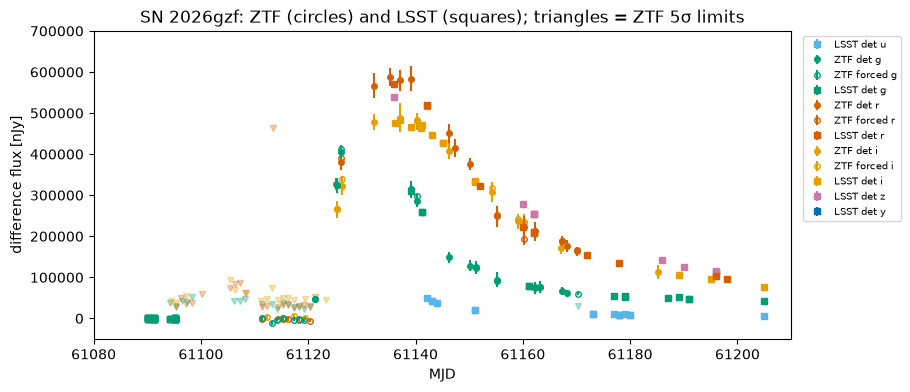

In [20]:
def mag_to_flux(mag):
    return 10 ** (-0.4 * (np.asarray(mag, float) - 31.4))


def ztf_diff_flux(df, mag="mag", err="e_mag"):
    df = df.copy()
    df.loc[df[err] >= 100, err] = np.nan
    df["flux"] = np.where(df.isdiffpos < 0, -1, 1) * mag_to_flux(df[mag])
    df["flux_err"] = 0.4 * np.log(10) * df.flux.abs() * df[err]
    return df


ztf_fp_flux = ztf_diff_flux(ztf_fp)
ztf_det_flux = ztf_diff_flux(ztf_det, "magpsf", "sigmapsf")

# ALeRCE plotting conventions: colour per band (same in ZTF and LSST), drawing order with g on top and y at the
# bottom, and legends sorted by wavelength
BAND_COLORS = {"u": "#56B4E9", "g": "#009E73", "r": "#D55E00", "i": "#E69F00", "z": "#CC79A7", "y": "#0072B2"}
BAND_ZORDER = {"u": 2, "g": 6, "r": 5, "i": 4, "z": 3, "y": 1}
BAND_ORDER = ["u", "g", "r", "i", "z", "y"]

fig, ax = plt.subplots(figsize=(9, 4))
entries = []                                   # (band, label, artist) for the sorted legend
for (sid, label, df, fx, fe, marker) in [
        (0, "ZTF det", ztf_det_flux, "flux", "flux_err", "o"),
        (0, "ZTF forced", ztf_fp_flux, "flux", "flux_err", "o"),
        (1, "LSST det", lsst_det, "psfflux", "psffluxerr", "s")]:
    for band, g in df.assign(sid=sid).pipe(decode).groupby("band_name"):
        artist = ax.errorbar(g.mjd, g[fx], g[fe], fmt=marker, ms=4, color=BAND_COLORS[band],
                             mfc="none" if "forced" in label else BAND_COLORS[band], zorder=BAND_ZORDER[band])
        entries.append((band, f"{label} {band}", artist))
for band, g in ztf_nd.assign(sid=0).pipe(decode).groupby("band_name"):
    ax.plot(g.mjd, mag_to_flux(g.diffmaglim), "v", color=BAND_COLORS[band], alpha=0.3, ms=4, zorder=0)
entries.sort(key=lambda e: BAND_ORDER.index(e[0]))   # stable sort: keeps ZTF det, ZTF forced, LSST within a band
ax.legend([e[2] for e in entries], [e[1] for e in entries], fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_xlim(61080, 61210)
ax.set_ylim(-0.05e6, 0.7e6)                  # a few shallow ZTF limits (bad nights) would stretch the axis
ax.set_xlabel("MJD")
ax.set_ylabel("difference flux [nJy]")
ax.set_title("SN 2026gzf: ZTF (circles) and LSST (squares); triangles = ZTF 5σ limits");

The two surveys agree. Small offsets are expected: ZTF and Rubin filters are not identical.

### 5.4 A reusable light-curve function

The library `alerce_ms.get_lightcurve(oid, sid)` does all of the above for either survey and returns one
standard table with `diff_flux`, `sci_flux` (both in nJy), `diff_mag`, `sci_mag`, `band_name`, `survey` and
`kind` (`det` / `forced`). Read its source in `alerce_ms.py`: it is the same code as above.

## 6. ZTF auxiliary tables

ZTF alerts carry extra context, stored per detection (`measurement_id`):

| Table | Content |
|---|---|
| `ztf_ps1` | 3 closest Pan-STARRS1 sources: magnitudes, star/galaxy score `sgscore` (1 = star), distance `distpsnr` |
| `ztf_gaia` | nearest Gaia source and nearest bright Gaia source (distance, magnitude) |
| `ztf_ss` | nearest known solar-system object (MPC): distance `ssdistnr`, magnitude, name (−999 = none) |
| `ztf_dataquality` | image/PSF quality: FWHM, χ² of the PSF fit, number of bad pixels, zero points… |
| `ztf_reference` | reference (template) image used for each band: dates, number of frames, nearest source in it |

In [21]:
tap_query(f"""
    SELECT TOP 3 measurement_id, objectidps1, sgmag1, srmag1, simag1, sgscore1, distpsnr1, nmtchps
    FROM alerce_tap.ztf_ps1 WHERE oid = {sn_oid}
""")

,measurement_id,objectidps1,sgmag1,srmag1,simag1,sgscore1,distpsnr1,nmtchps
0,3367316265315015017,108501499287012488,19.4995,19.8514,-999.0,0.026833,0.189624,7
1,3371211265315015010,108501499287012488,19.4995,19.8514,-999.0,0.026833,0.210201,7
2,3371269055315015008,108501499287012488,19.4995,19.8514,-999.0,0.026833,0.162463,7


The closest PS1 source is 0.2″ away with `sgscore1 ≈ 0.03`: a **galaxy**. The supernova exploded near the
centre of its host, as seen by Pan-STARRS.

In [22]:
tap_query(f"SELECT * FROM alerce_tap.ztf_gaia WHERE oid = {sn_oid}")

,oid,measurement_id,neargaia,neargaiabright,maggaia,maggaiabright,created_date
0,36029005852662990,3431211435315015003,57.747448,-999.0,17.039898,-999.0,2026-07-10


In [23]:
tap_query(f"SELECT TOP 3 measurement_id, ssdistnr, ssmagnr, ssnamenr FROM alerce_tap.ztf_ss WHERE oid = {sn_oid}")

,measurement_id,ssdistnr,ssmagnr,ssnamenr
0,3367316265315015017,-999.0,-999.0,
1,3371211265315015010,-999.0,-999.0,
2,3371269055315015008,-999.0,-999.0,


In [24]:
tap_query(f"""
    SELECT TOP 5 measurement_id, fwhm, chipsf, classtar, nbad, seeratio, magzpsci
    FROM alerce_tap.ztf_dataquality WHERE oid = {sn_oid}
""")

,measurement_id,fwhm,chipsf,classtar,nbad,seeratio,magzpsci
0,3367316265315015017,2.65,1.356967,0.946,0,1.090376,26.201454
1,3371211265315015010,2.25,4.392919,0.984,0,1.193595,26.242571
2,3371269055315015008,1.98,6.870788,1.000,0,1.235792,25.512106
3,3371321755315015006,2.57,5.893991,0.984,0,1.039471,25.974001
4,3372162295315015010,2.29,11.812821,0.984,0,1.061717,26.230267


In [25]:
ref = tap_query(f"""
    SELECT band, rfid, field, rcid, magnr, sigmagnr, mjdstartref, mjdendref, nframesref
    FROM alerce_tap.ztf_reference WHERE oid = {sn_oid}
""")
ref.assign(sid=0).pipe(decode)

,band,rfid,field,rcid,magnr,sigmagnr,mjdstartref,mjdendref,nframesref,sid,survey_name,band_name
0,3,417120353,417,53,19.898001,0.093,59202.474167,59527.522049,15,0,ZTF,i
1,1,417120153,417,53,19.221001,0.046,58202.254676,58441.484757,23,0,ZTF,g
2,2,417120253,417,53,19.735001,0.053,58165.395613,58449.522870,30,0,ZTF,r


The templates were built from 15–30 images taken in 2018–2021, long before the explosion: good.

## 7. LSST solar-system tables (`sid = 2`)

Moving objects detected by Rubin are associated with known asteroids. `lsst_ss_detection` holds the observing
geometry of every detection; `lsst_mpc_orbits` holds the Minor Planet Center orbit. `lsst_ss_object` (the
per-asteroid summary, `sid = 2`) is not filled yet.

In [26]:
tap_query("SELECT TOP 3 * FROM alerce_tap.lsst_ss_object")

,oid,designation,nobs,arc,firstobservationmjdtai,moidearth,moidearthdeltav,moideartheclipticlongitude,moidearthtrueanomaly,moidearthtrueanomalyobject,tisserand_j,extendednessmax,extendednessmedian,extendednessmin,u_nobs,u_h,u_herr,u_g12,u_g12err,u_h_u_g12_cov,...,z_g12,z_g12err,z_h_z_g12_cov,z_nobsused,z_chi2,z_phaseanglemin,z_phaseanglemax,z_slope_fit_failed,y_nobs,y_h,y_herr,y_g12,y_g12err,y_h_y_g12_cov,y_nobsused,y_chi2,y_phaseanglemin,y_phaseanglemax,y_slope_fit_failed,created_date


In [27]:
tap_query("""
    SELECT TOP 5 measurement_id, ssobjectid, designation, heliorange, toporange, phaseangle, elongation
    FROM alerce_tap.lsst_ss_detection
""")

,measurement_id,ssobjectid,designation,heliorange,toporange,phaseangle,elongation
0,170560743431209009,20607267131895873,A863 EA,3.123901,2.663057,18.065046,107.576248
1,170534263631380519,20608375535448129,A875 WA,2.252464,2.434042,24.641024,67.620125
2,170534263885136101,20608375535448129,A875 WA,2.252461,2.434054,24.640923,67.619392
3,170538716555640840,20608375535448129,A875 WA,2.250754,2.442921,24.557983,67.067757
4,170538716692480033,20608375535448129,A875 WA,2.250751,2.442939,24.557825,67.066658


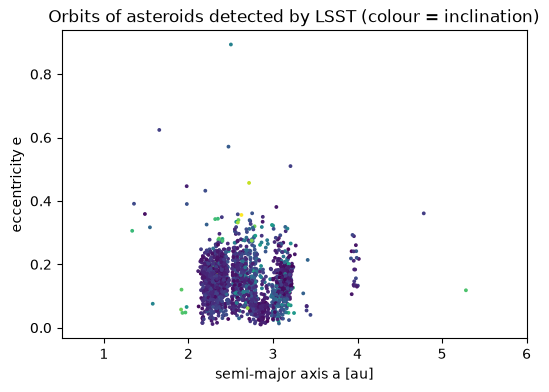

In [28]:
orbits = tap_query("SELECT TOP 2000 ssobjectid, designation, a, e, i, q, h FROM alerce_tap.lsst_mpc_orbits")
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(orbits.a, orbits.e, s=3, c=orbits.i, cmap="viridis")
ax.set_xlim(0.5, 6)
ax.set_xlabel("semi-major axis a [au]")
ax.set_ylabel("eccentricity e")
ax.set_title("Orbits of asteroids detected by LSST (colour = inclination)");

Kirkwood gaps of the main belt are already visible near 2.5 and 2.8 au.

## 8. Derived products

### 8.1 `magstat`: per-band magnitude statistics

One row per object and band: mean/median/min/max magnitude, first/last magnitude, `dmdt_first` (how fast it rose)…
Currently filled for **ZTF only**.

In [29]:
tap_query(f"""
    SELECT oid, sid, band, n_det, magmean, magmin, magmax, magfirst, maglast, dmdt_first, saturation_rate
    FROM alerce_tap.magstat WHERE oid = {sn_oid} AND sid = 0
""").pipe(decode)

,oid,sid,band,n_det,magmean,magmin,magmax,magfirst,maglast,dmdt_first,saturation_rate,survey_name,band_name
0,36029005852662990,0,1,13,18.617567,17.380268,19.699455,19.699455,19.435547,-0.353721,0.0,ZTF,g
1,36029005852662990,0,2,15,17.600721,16.977577,18.366873,17.614571,18.366873,-0.542422,0.0,ZTF,r
2,36029005852662990,0,3,11,17.738005,17.176901,18.769842,17.840105,18.769842,-0.952559,NaN,ZTF,i


### 8.2 `feature`: light-curve features in *long* format

One row per `(oid, sid, feature_id, band)`. A few details:
* the value column is called `feature_value` in TAP (`value` is a reserved word in ADQL);
* `band = 0` means "no band" (e.g. `W1-W2`), and multi-digit bands are combinations (`12` = g+r);
* only the **latest** version of each feature is kept (`version` → `feature_version_lut`).

In [30]:
rrl_oid = ztf_name_to_oid("ZTF17aabhbva")
feats = tap_query(f"""
    SELECT f.oid, f.sid, f.feature_id, f.band, f.version, f.feature_value
    FROM alerce_tap.feature AS f
    WHERE f.oid = {rrl_oid} AND f.sid = 0
""").pipe(decode)
print(len(feats), "feature values")
feats[feats.feature_name.isin(["Multiband_period", "Period_band", "Amplitude", "g-r_mean", "W1-W2", "PPE"])]

205 feature values


,oid,sid,feature_id,band,version,feature_value,survey_name,band_name,feature_name
0,36028933560318190,0,0,12,1,0.021785,ZTF,gr,g-r_mean
4,36028933560318190,0,4,0,1,0.426000,ZTF,,W1-W2
40,36028933560318190,0,30,12,1,0.488863,ZTF,gr,Multiband_period
41,36028933560318190,0,31,12,1,0.032670,ZTF,gr,PPE
42,36028933560318190,0,32,1,1,0.488863,ZTF,g,Period_band
43,36028933560318190,0,32,2,1,0.488863,ZTF,r,Period_band
86,36028933560318190,0,57,1,1,0.769783,ZTF,g,Amplitude
87,36028933560318190,0,57,2,1,0.581715,ZTF,r,Amplitude


The RR Lyrae star has a period of **0.4889 days** in both g and r. We can pivot to a *wide* table with one column
per feature and band:

In [31]:
feats["col"] = feats.feature_name + np.where(feats.band_name != "", "_" + feats.band_name, "")
feats.pivot_table(index="oid", columns="col", values="feature_value").iloc[:, :12]

col,Amplitude_g,Amplitude_r,AndersonDarling_g,AndersonDarling_r,Autocor_length_g,Autocor_length_r,Beyond1Std_g,Beyond1Std_r,Con_g,Con_r,Coordinate_x,Coordinate_y
oid,,,,,,,,,,,,
36028933560318190,0.769783,0.581715,1.0,1.0,1.0,17.0,0.508876,0.452778,0.0,0.0,-0.867264,0.497276


It is usually better to filter features in ADQL by joining `feature_name_lut`, so the server only sends what you need:

In [32]:
tap_query(f"""
    SELECT f.oid, n.feature_name, f.band, f.feature_value
    FROM alerce_tap.feature AS f
    JOIN alerce_tap.feature_name_lut AS n ON n.sid = f.sid AND n.feature_id = f.feature_id
    WHERE f.oid = 313888627082919999 AND f.sid = 1
      AND n.feature_name IN ('Multiband_period', 'Period_band')
""").assign(sid=1).pipe(decode)

,oid,feature_name,band,feature_value,sid,survey_name,band_name
0,313888627082919999,Multiband_period,0,0.977937,1,LSST DIA Object,
1,313888627082919999,Period_band,1,0.977937,1,LSST DIA Object,g
2,313888627082919999,Period_band,2,0.960521,1,LSST DIA Object,r
3,313888627082919999,Period_band,3,0.489406,1,LSST DIA Object,i
4,313888627082919999,Period_band,4,0.977937,1,LSST DIA Object,z
5,313888627082919999,Period_band,5,0.987038,1,LSST DIA Object,y


Interesting! This is the **LSST** counterpart of the same RR Lyrae star, and its multiband period is ~0.978 d,
**twice** the ZTF value. Only the i band finds 0.489 d. We will come back to this alias in notebook 05.

### 8.3 `probability`: classifications

One row per `(oid, sid, classifier_id, class_id)`, with the probability and its `ranking` within that classifier
(1 = most probable class). `lastmjd` records which data the prediction used.

In [33]:
probs = tap_query(f"""
    SELECT oid, sid, classifier_id, class_id, classifier_version, probability, ranking, lastmjd
    FROM alerce_tap.probability
    WHERE oid = {sn_oid} AND sid = 0 AND ranking <= 3
""").pipe(decode)
probs.sort_values(["classifier_name", "ranking"])[["classifier_name", "class_name", "probability", "ranking"]]

,classifier_name,class_name,probability,ranking
6,lc_classifier_BHRF_forced_phot,SESN,0.426496,1
8,lc_classifier_BHRF_forced_phot,SNIa,0.205632,2
7,lc_classifier_BHRF_forced_phot,SNII,0.186592,3
20,lc_classifier_BHRF_forced_phot_periodic,RRLab,0.364000,1
18,lc_classifier_BHRF_forced_phot_periodic,CEP,0.300000,2
19,lc_classifier_BHRF_forced_phot_periodic,EA,0.080000,3
15,lc_classifier_BHRF_forced_phot_stochastic,CV/Nova,0.648000,1
16,lc_classifier_BHRF_forced_phot_stochastic,Microlensing,0.132000,2
17,lc_classifier_BHRF_forced_phot_stochastic,YSO,0.080000,3
11,lc_classifier_BHRF_forced_phot_top,Transient,0.952000,1


The hierarchical light-curve classifier says **Transient** (top level, P = 0.95) and, within transients, **SESN**
(stripped-envelope SN, P = 0.43). TNS classified it as a type Ic-BL: a stripped-envelope SN. 🎉

> ⚠️ `classifier_version` in `probability` is a lossy integer ("2.2.0" → 220). Use `classifier.classifier_version`.

**Selecting samples** is where `probability` shines. The partial index on `ranking = 1` makes this fast:
the 10 most probable LSST supernova candidates according to the newest Rubin stamp classifier:

In [34]:
cid = classifier_lut.query("classifier_name == 'stamp_classifier_rubin_beta_20260421'").classifier_id.iloc[0]
sn_class = taxonomy_lut.query("classifier_id == @cid and class_name == 'SN'").class_id.iloc[0]
tap_query(f"""
    SELECT TOP 10 p.oid, p.sid, p.probability, o.meanra, o.meandec, o.firstmjd, o.n_det
    FROM alerce_tap.probability AS p
    JOIN alerce_tap.object AS o ON o.oid = p.oid AND o.sid = p.sid
    WHERE p.sid = 1 AND p.classifier_id = {cid} AND p.class_id = {sn_class}
      AND p.ranking = 1 AND p.probability > 0.8
    ORDER BY p.probability DESC
""")

,oid,sid,probability,meanra,meandec,firstmjd,n_det
0,170587116145737778,1,0.995165,328.677659,-16.623497,61217.413106,2
1,170661828815749513,1,0.994916,222.659230,-37.888798,61234.049815,2
2,170595943059554358,1,0.994499,358.887798,2.082098,61219.412591,5
3,170591542833053740,1,0.994455,341.329446,-16.101054,61218.409344,1
4,170653061547032670,1,0.993627,331.995517,-18.251400,61232.353607,3
5,170437565342548730,1,0.993592,246.846369,-29.668975,61183.284527,2
6,170635505405264453,1,0.993479,305.777124,-27.521201,61228.335763,1
7,170587105380008163,1,0.993321,334.017397,-19.103191,61217.367901,8
8,170433140619739440,1,0.993183,239.189592,-15.992809,61182.231132,5
9,170591513501762367,1,0.993137,298.816591,-12.217869,61218.292019,4


## 9. Crossmatches

`xmatch` links each object to its nearest counterpart in external catalogs stored *inside* the database:
AllWISE (`catid = 0`, mid-infrared + 2MASS) and Gaia DR3 (`catid = 1`). Join to the catalog tables on `oid_catalog`.
Let us look at the LSST counterpart of the quasar:

In [35]:
tap_query("""
    SELECT x.catid, x.oid_catalog, x.dist,
           a.w1mpro, a.w2mpro, a.w3mpro, a.w4mpro, a.w1mpro - a.w2mpro AS w1_w2, a.k_m_2mass,
           g.phot_g_mean_mag, g.bp_rp, g.parallax, g.pm, g.in_qso_candidates, g.classprob_dsc_combmod_quasar
    FROM alerce_tap.xmatch AS x
    LEFT JOIN alerce_tap.allwise AS a ON x.catid = 0 AND a.oid_catalog = x.oid_catalog
    LEFT JOIN alerce_tap.gaiadr3_source AS g ON x.catid = 1 AND g.oid_catalog = x.oid_catalog
    WHERE x.oid = 313985345706262538 AND x.sid = 1
""").pipe(decode)

,catid,oid_catalog,dist,w1mpro,w2mpro,w3mpro,w4mpro,w1_w2,k_m_2mass,phot_g_mean_mag,bp_rp,parallax,pm,in_qso_candidates,classprob_dsc_combmod_quasar,catalog_name
0,0,1512p030_ac51-062173,0.041923,14.489,13.182,10.004,7.57,1.307,15.746,NaN,NaN,NaN,NaN,NaN,NaN,AllWISE
1,1,3836874364905765248,0.029281,NaN,NaN,NaN,NaN,NaN,NaN,17.669119,0.682604,-0.706931,0.516961,True,0.998375,GaiaDR3_source


W1 − W2 = 1.3 (AGN have W1 − W2 > 0.8, Stern et al. 2012), zero parallax and proper motion, and Gaia's classifier
gives P(quasar) = 0.998. A textbook quasar. In notebook 04 we add X-ray, UV and spectroscopic redshifts.

## 10. Rules of thumb

1. **Join on `(oid, sid)`**; ZTF extension tables have no `sid`, join them on `oid` (+ `measurement_id`).
2. **Decode integers with their key**: bands and features with `sid`, classes with `classifier_id`.
3. **Use `TOP N`** while exploring, and filter on indexed columns (`oid`, `sid`, `ranking = 1`, `probability`,
   positions via `CONTAINS`).
4. **Select the page first, then join** large tables (sub-query with `TOP` → join `feature`, `detection`, …).
5. Avoid `COUNT(*)` or filters on non-indexed columns over the huge tables (`detection` has ~660 million rows,
   `feature` ~1.4 billion): they can take minutes.
6. ZTF: magnitudes, UTC, error 100 = n/a. LSST: nJy fluxes, TAI, `m = 31.4 − 2.5 log10 F`.
7. There is **no** LSST non-detection table and **no** LSST `magstat` yet.

### The `alerce_ms` library

Everything we wrote here (plus caching, retries, the REST API, catsHTM and the experimental explorer) is collected
in `alerce_ms.py`. From now on we just import it:

In [36]:
import alerce_ms as am

[name for name in dir(am) if not name.startswith("_") and callable(getattr(am, name))]

['angular_sep_arcsec',
 'api_get',
 'as_oid',
 'band_key',
 'band_label',
 'catshtm_crossmatch',
 'class_id',
 'classifier_id',
 'decode',
 'display_name',
 'explorer_url',
 'explorer_xmatch',
 'feature_ids',
 'find_counterparts',
 'flux_to_mag',
 'get_features',
 'get_json',
 'get_lightcurve',
 'get_magstats',
 'get_object',
 'get_probabilities',
 'get_stamps',
 'get_xmatch',
 'get_ztf_non_detections',
 'load_luts',
 'mag_to_flux',
 'oid_to_ztf_name',
 'phase_fold',
 'plot_folded',
 'plot_lightcurve',
 'plot_stamps',
 'show_link',
 'sort_legend',
 'tap_columns',
 'tap_cone',
 'tap_query',
 'tap_service',
 'tap_tables',
 'ztf_name_to_oid']

In [37]:
am.get_probabilities("ZTF20acyxpwi", sid=0).query("ranking == 1")[["classifier_name", "class_name", "probability"]]

,classifier_name,class_name,probability
0,lc_classifier_BHRF_forced_phot,QSO,0.831360
21,lc_classifier_BHRF_forced_phot_periodic,Periodic-Other,0.270000
30,lc_classifier_BHRF_forced_phot_stochastic,QSO,0.866000
36,lc_classifier_BHRF_forced_phot_top,Stochastic,0.960000
39,lc_classifier_BHRF_forced_phot_transient,TDE,0.240000
45,stamp_classifier,AGN,0.671827
50,stamp_classifier_2025_beta,AGN,0.630962


### ✏️ Exercises

1. **(easy)** Which bands has the LSST counterpart of the supernova been detected in? Use `am.get_lightcurve` and
   `groupby("band_name")`.
2. **(easy)** Decode `feature.band = 12` for ZTF and for LSST with `am.band_label`. Do they mean the same thing?
3. **(medium)** Write an ADQL query returning the 20 ZTF objects with the highest probability of being `RRLab`
   according to `lc_classifier_BHRF_forced_phot_periodic`, together with their `Multiband_period`.
   Hint: select the page in a sub-query, then join `feature` and `feature_name_lut`.
4. **(medium)** For the quasar `ZTF20acyxpwi`, find the `ztf_ps1` star/galaxy score and the `ztf_gaia` nearest
   source. Are they consistent with what Gaia DR3 says in `xmatch`?
5. **(challenge)** Plot the distribution of `h` (absolute magnitude) of LSST asteroids in `lsst_mpc_orbits` for
   `a < 2.5 au` and `a > 2.8 au`. Which population is fainter on average? Why?

In [38]:
# your code here

**Next:** [02 · One source, two surveys](02_one_source_two_surveys.ipynb)